# 📊 Feature-by-Feature Visualization Around COVID-19 Onset ($\tau = 0$)

Using the cleaned non-redundant dataset (`data/covid_mortality_simple.csv`), this notebook inspects:
1. The **4-panel benchmark verification figure** (Train vs Test excess mortality, raw all-cause counts, exogenous case/stringency forcing, and iconic European NUTS-3 curves).
2. **What happens around $\tau = 0$ for every dynamic feature** across all `505` regions (`Train = 314`, `Test = 191`).
3. A **single-region multi-feature walkthrough** (`PL911` Miasto Warszawa, Fall 2020 Test split).
4. A quantitative **before vs. after $\tau = 0$ distribution summary** across all kept features.

### 1. Load Libraries and the Simple Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the clean, non-redundant simple dataset (one row per region per week)
df = pd.read_csv('data/covid_mortality_simple.csv')

print(f'Loaded simple dataset: {df.shape[0]:,} rows x {df.shape[1]} columns')
print(f'Unique regions: {df["sample_id"].nunique()} '
      f'(Train={df[df["split"] == "train"]["sample_id"].nunique()}, '
      f'Test={df[df["split"] == "test"]["sample_id"].nunique()})')
df.head(3)

Loaded simple dataset: 20,705 rows x 27 columns
Unique regions: 505 (Train=314, Test=191)


,sample_id,region_id,region_name,country_code,split,onset_week,iso_week,tau_week,latitude,longitude,...,covid_deaths_100k,stringency_index,economic_support_index,deaths_vs_4w_avg_diff,temp_c,humidity_pct,pressure_hpa,wind_ms,rain_mm_week,week_of_year
0,0,ITC11,Torino,IT,train,2020-W10,2019-W38,-24,45.1411,7.44703,...,0.0,0.0,0.0,13.75,17.354286,68.78714,938.40000,2.135714,11.96,38
1,0,ITC11,Torino,IT,train,2020-W10,2019-W39,-23,45.1411,7.44703,...,0.0,0.0,0.0,-24.25,17.598572,57.87143,933.00000,1.831428,4.20,39
2,0,ITC11,Torino,IT,train,2020-W10,2019-W40,-22,45.1411,7.44703,...,0.0,0.0,0.0,-1.00,15.182858,55.31286,929.95715,2.240000,8.67,40


### 2. 4-Panel Overview Diagram (Reproducible Code for Benchmark Verification Plot)

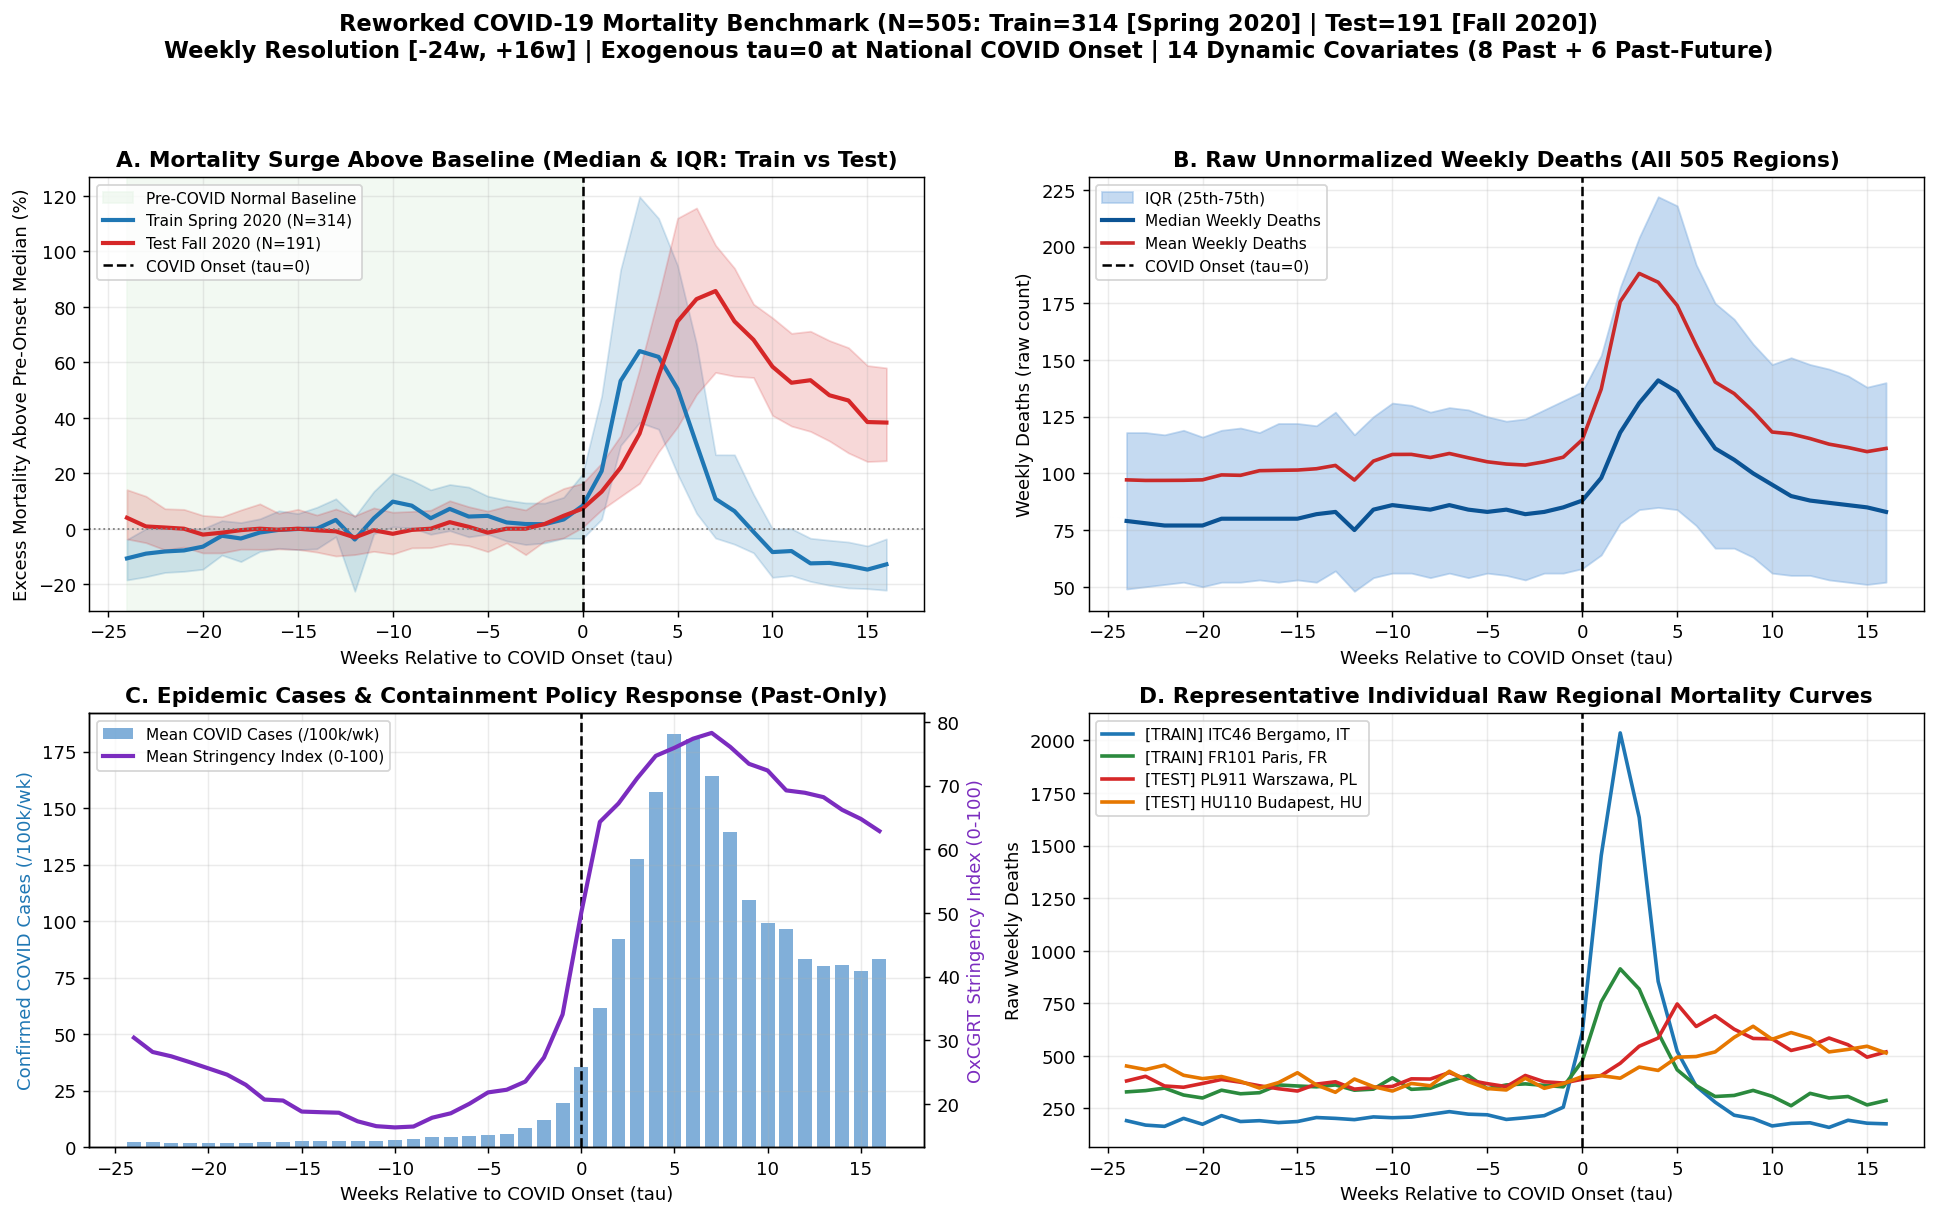

In [2]:
# Compute each region's normal pre-onset median weekly deaths (using tau < 0)
pre_median = (
    df[df['tau_week'] < 0]
    .groupby('sample_id')['deaths_total']
    .median()
    .rename('pre_median_deaths')
)
df = df.merge(pre_median, on='sample_id')
df['excess_pct'] = (df['deaths_total'] / df['pre_median_deaths'] - 1.0) * 100.0

fig, axes = plt.subplots(2, 2, figsize=(15, 9.5), dpi=130)
fig.suptitle(
    'Reworked COVID-19 Mortality Benchmark (N=505: Train=314 [Spring 2020] | Test=191 [Fall 2020])\n'
    'Weekly Resolution [-24w, +16w] | Exogenous tau=0 at National COVID Onset | 14 Dynamic Covariates (8 Past + 6 Past-Future)',
    fontsize=12.5,
    fontweight='bold',
    y=0.98,
)

# --- Panel A: Percent Mortality Change Above Baseline (Train vs Test Median & IQR) ---
ax = axes[0, 0]
ax.axvspan(-24, 0, color='#e8f5e9', alpha=0.55, label='Pre-COVID Normal Baseline')
for split_name, color, label in [('train', '#1f77b4', 'Train Spring 2020 (N=314)'),
                                 ('test', '#d62728', 'Test Fall 2020 (N=191)')]:
    sub = df[df['split'] == split_name]
    g = sub.groupby('tau_week')['excess_pct'].agg(
        med='median',
        q25=lambda s: np.percentile(s, 25),
        q75=lambda s: np.percentile(s, 75),
    ).reset_index()
    ax.plot(g['tau_week'], g['med'], color=color, lw=2.3, label=label)
    ax.fill_between(g['tau_week'], g['q25'], g['q75'], color=color, alpha=0.18)

ax.axvline(0, color='black', ls='--', lw=1.4, label='COVID Onset (tau=0)')
ax.axhline(0, color='gray', ls=':', lw=1.0)
ax.set_title('A. Mortality Surge Above Baseline (Median & IQR: Train vs Test)', fontweight='bold')
ax.set_xlabel('Weeks Relative to COVID Onset (tau)')
ax.set_ylabel('Excess Mortality Above Pre-Onset Median (%)')
ax.grid(True, alpha=0.25)
ax.legend(loc='upper left', fontsize=8.5)

# --- Panel B: Raw Unnormalized Weekly Deaths Across All 505 Regions ---
ax = axes[0, 1]
raw_stats = df.groupby('tau_week')['deaths_total'].agg(
    med='median',
    mean='mean',
    q25=lambda s: np.percentile(s, 25),
    q75=lambda s: np.percentile(s, 75),
).reset_index()
ax.fill_between(raw_stats['tau_week'], raw_stats['q25'], raw_stats['q75'], color='#7faee0', alpha=0.45, label='IQR (25th-75th)')
ax.plot(raw_stats['tau_week'], raw_stats['med'], color='#0b5394', lw=2.3, label='Median Weekly Deaths')
ax.plot(raw_stats['tau_week'], raw_stats['mean'], color='#c92a2a', lw=2.0, label='Mean Weekly Deaths')
ax.axvline(0, color='black', ls='--', lw=1.4, label='COVID Onset (tau=0)')
ax.set_title('B. Raw Unnormalized Weekly Deaths (All 505 Regions)', fontweight='bold')
ax.set_xlabel('Weeks Relative to COVID Onset (tau)')
ax.set_ylabel('Weekly Deaths (raw count)')
ax.grid(True, alpha=0.25)
ax.legend(loc='upper left', fontsize=8.5)

# --- Panel C: Mean COVID Case Wave & Lockdown Policy Stringency ---
ax = axes[1, 0]
ax_r = ax.twinx()
ep = df.groupby('tau_week')[['covid_cases_100k', 'stringency_index']].mean().reset_index()
b_cases = ax.bar(ep['tau_week'], ep['covid_cases_100k'], width=0.75, color='#3d85c6', alpha=0.65, label='Mean COVID Cases (/100k/wk)')
l_str, = ax_r.plot(ep['tau_week'], ep['stringency_index'], color='#7b2cbf', lw=2.3, label='Mean Stringency Index (0-100)')
ax.axvline(0, color='black', ls='--', lw=1.4)
ax.set_title('C. Epidemic Cases & Containment Policy Response (Past-Only)', fontweight='bold')
ax.set_xlabel('Weeks Relative to COVID Onset (tau)')
ax.set_ylabel('Confirmed COVID Cases (/100k/wk)', color='#1f77b4')
ax_r.set_ylabel('OxCGRT Stringency Index (0-100)', color='#7b2cbf')
ax.grid(True, alpha=0.25)
ax.legend([b_cases, l_str], [b_cases.get_label(), l_str.get_label()], loc='upper left', fontsize=8.5)

# --- Panel D: Representative Individual Raw Regional Mortality Curves ---
ax = axes[1, 1]
rep_regions = [
    ('ITC46', '#1f77b4', '[TRAIN] ITC46 Bergamo, IT'),
    ('FR101', '#2b8a3e', '[TRAIN] FR101 Paris, FR'),
    ('PL911', '#d62728', '[TEST] PL911 Warszawa, PL'),
    ('HU110', '#e67700', '[TEST] HU110 Budapest, HU'),
]
for rid, col, lbl in rep_regions:
    sub = df[df['region_id'] == rid].sort_values('tau_week')
    ax.plot(sub['tau_week'], sub['deaths_total'], color=col, lw=2.0, label=lbl)

ax.axvline(0, color='black', ls='--', lw=1.4)
ax.set_title('D. Representative Individual Raw Regional Mortality Curves', fontweight='bold')
ax.set_xlabel('Weeks Relative to COVID Onset (tau)')
ax.set_ylabel('Raw Weekly Deaths')
ax.grid(True, alpha=0.25)
ax.legend(loc='upper left', fontsize=8.5)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig('data/covid_mortality_verification.png', dpi=150, bbox_inches='tight')
plt.show()

### 3. What Happens Around $\tau = 0$ for Every Single Feature

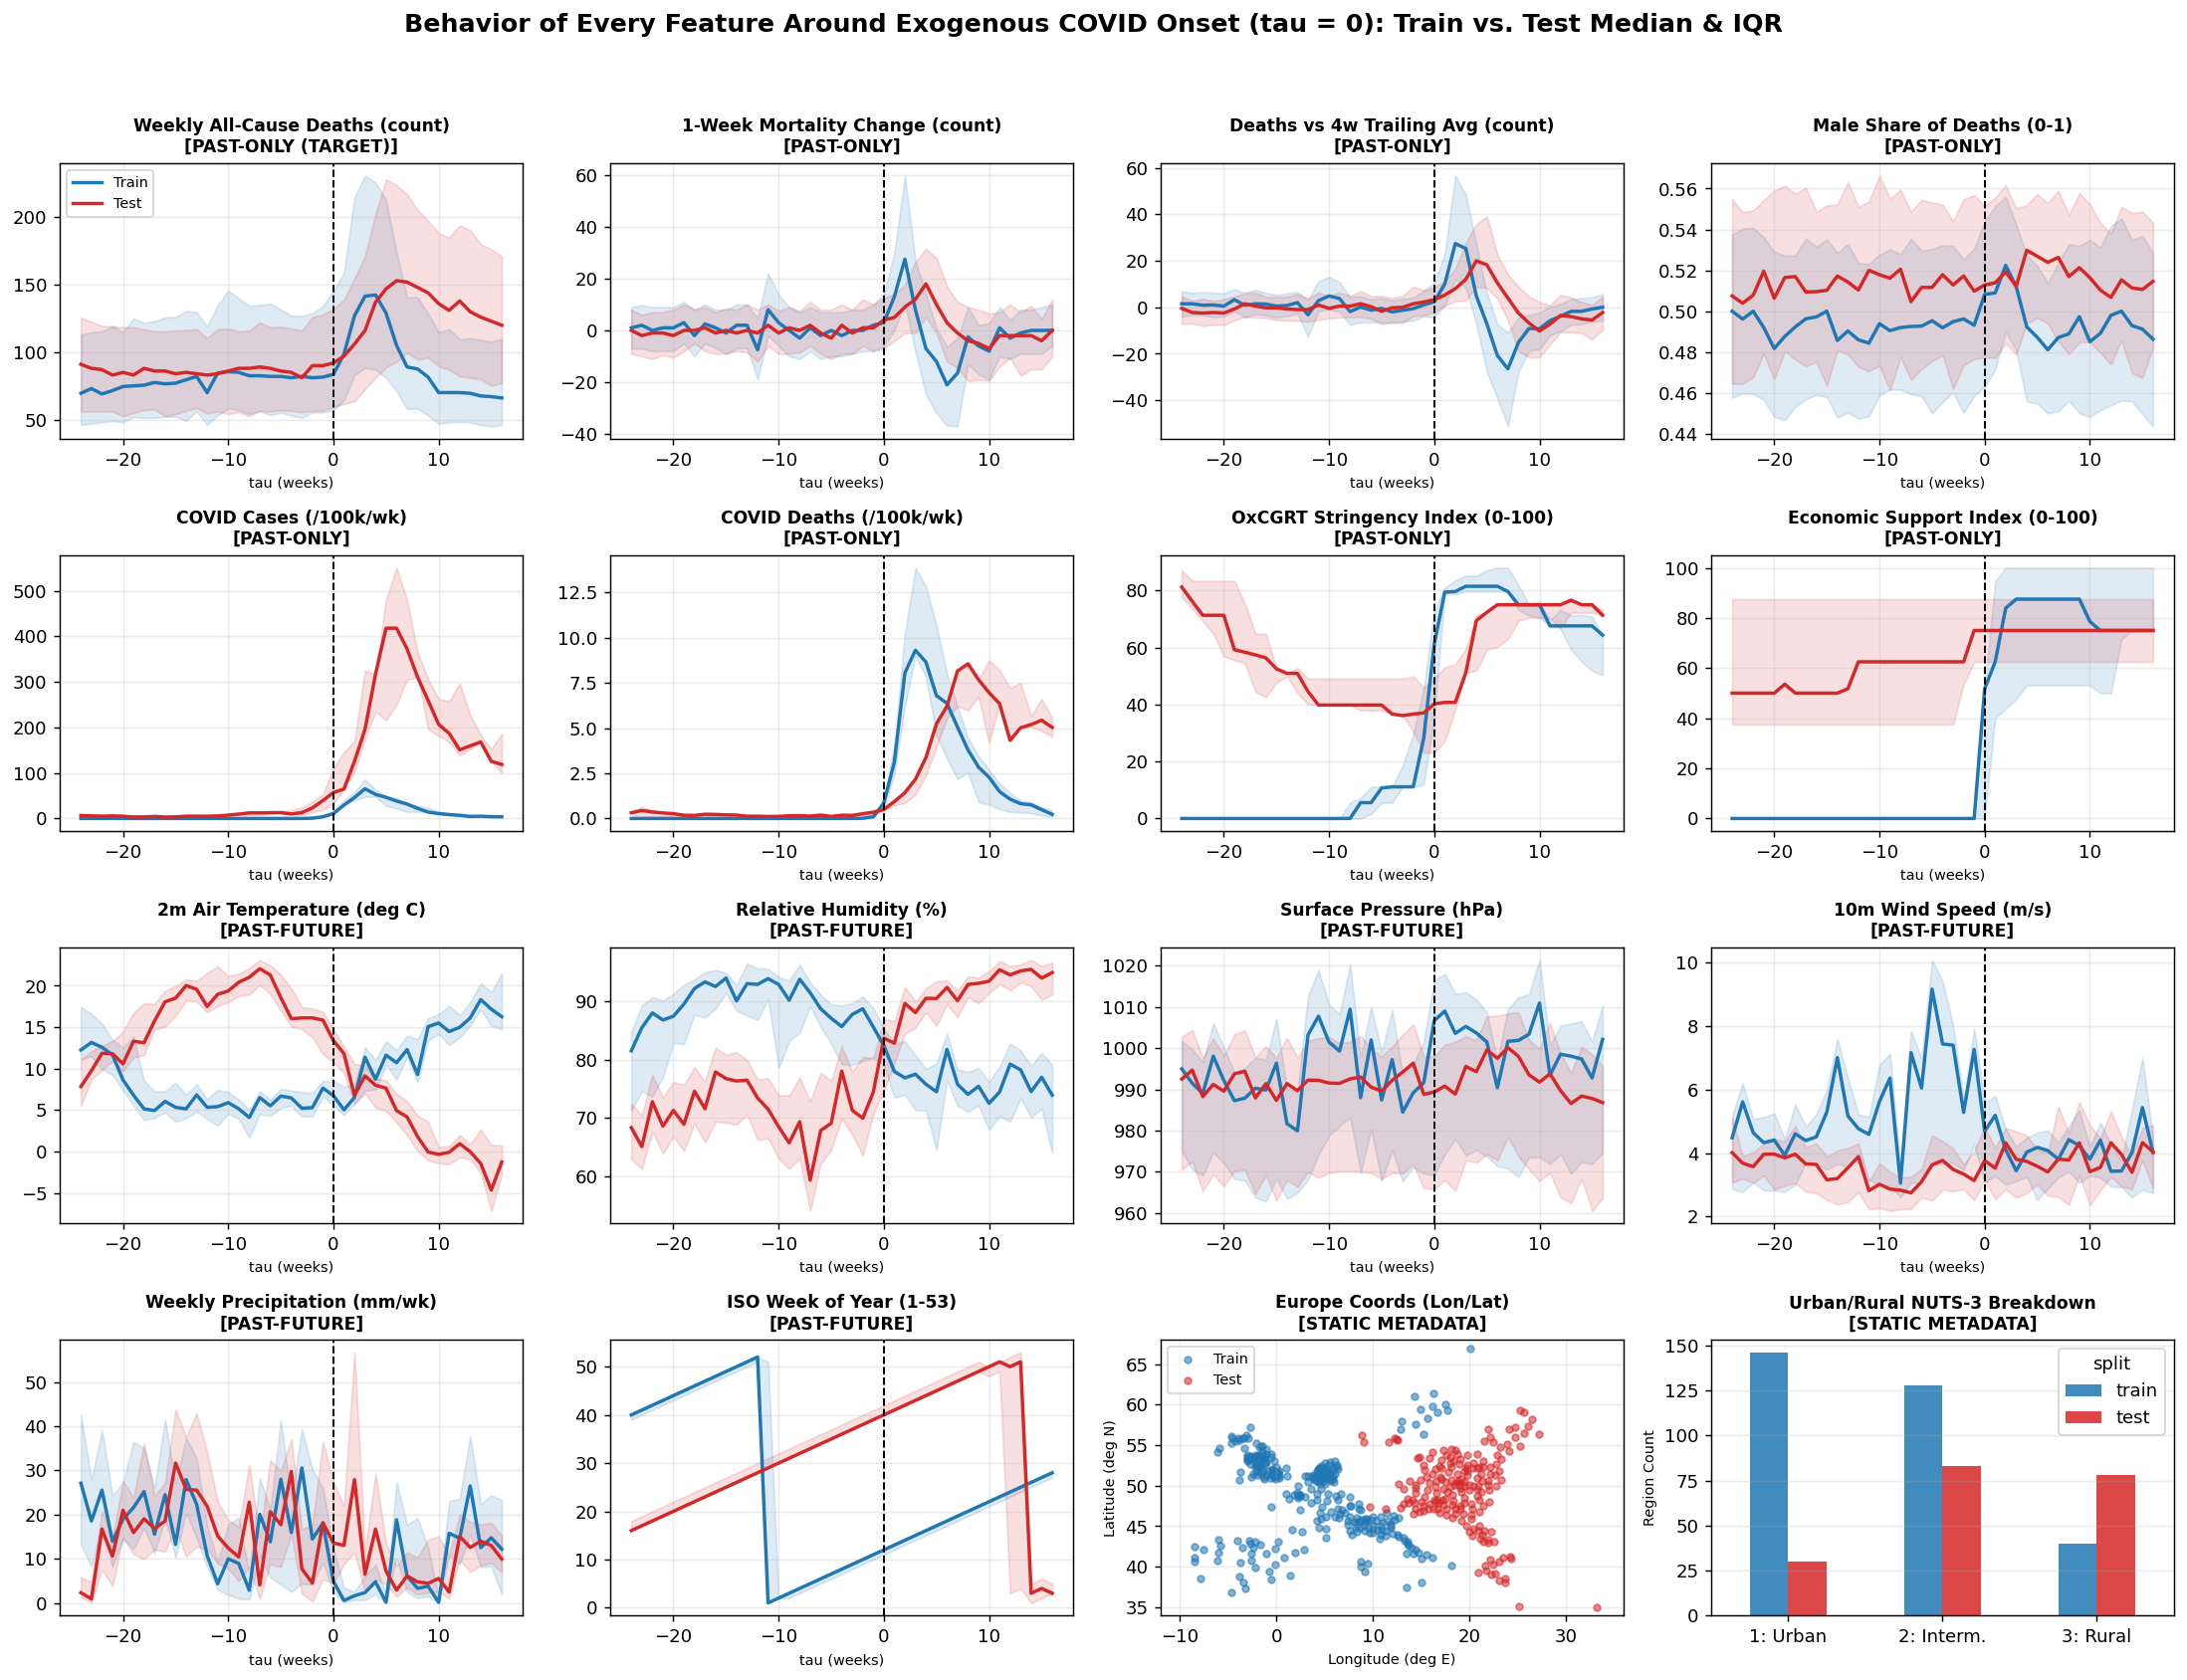

In [3]:
# Human-readable labels & units for all 14 dynamic features (8 past-only + 6 past-future)
FEATURES = [
    ('deaths_total', 'Weekly All-Cause Deaths (count)', 'PAST-ONLY (TARGET)'),
    ('deaths_change_1w', '1-Week Mortality Change (count)', 'PAST-ONLY'),
    ('deaths_vs_4w_avg_diff', 'Deaths vs 4w Trailing Avg (count)', 'PAST-ONLY'),
    ('male_death_share', 'Male Share of Deaths (0-1)', 'PAST-ONLY'),
    ('covid_cases_100k', 'COVID Cases (/100k/wk)', 'PAST-ONLY'),
    ('covid_deaths_100k', 'COVID Deaths (/100k/wk)', 'PAST-ONLY'),
    ('stringency_index', 'OxCGRT Stringency Index (0-100)', 'PAST-ONLY'),
    ('economic_support_index', 'Economic Support Index (0-100)', 'PAST-ONLY'),
    ('temp_c', '2m Air Temperature (deg C)', 'PAST-FUTURE'),
    ('humidity_pct', 'Relative Humidity (%)', 'PAST-FUTURE'),
    ('pressure_hpa', 'Surface Pressure (hPa)', 'PAST-FUTURE'),
    ('wind_ms', '10m Wind Speed (m/s)', 'PAST-FUTURE'),
    ('rain_mm_week', 'Weekly Precipitation (mm/wk)', 'PAST-FUTURE'),
    ('week_of_year', 'ISO Week of Year (1-53)', 'PAST-FUTURE'),
]

fig, axes = plt.subplots(4, 4, figsize=(17, 13), dpi=130)
axes = axes.flatten()

# Plot median curve and 25th-75th percentile band separately for Train and Test
for idx, (col, label, role) in enumerate(FEATURES):
    ax = axes[idx]
    for split_name, color, name in [('train', '#1f77b4', 'Train'), ('test', '#d62728', 'Test')]:
        sub = df[df['split'] == split_name]
        g = sub.groupby('tau_week')[col].agg(
            med='median',
            q25=lambda s: np.percentile(s, 25),
            q75=lambda s: np.percentile(s, 75),
        ).reset_index()
        ax.plot(g['tau_week'], g['med'], color=color, lw=1.9, label=name)
        ax.fill_between(g['tau_week'], g['q25'], g['q75'], color=color, alpha=0.14)

    ax.axvline(0, color='black', ls='--', lw=1.1)
    ax.set_title(f'{label}\n[{role}]', fontsize=9.5, fontweight='bold')
    ax.set_xlabel('tau (weeks)', fontsize=8)
    ax.grid(True, alpha=0.25)
    if idx == 0:
        ax.legend(loc='upper left', fontsize=8)

# Use remaining 2 grid slots cleanly for static region metadata summaries
meta_unique = df.drop_duplicates('sample_id')
ax_s1 = axes[14]
for split_name, color, name in [('train', '#1f77b4', 'Train'), ('test', '#d62728', 'Test')]:
    sub = meta_unique[meta_unique['split'] == split_name]
    ax_s1.scatter(sub['longitude'], sub['latitude'], s=14, alpha=0.55, color=color, label=name)
ax_s1.set_xlim(-12, 36)
ax_s1.set_ylim(34, 68)
ax_s1.set_title('Europe Coords (Lon/Lat)\n[STATIC METADATA]', fontsize=9.5, fontweight='bold')
ax_s1.set_xlabel('Longitude (deg E)', fontsize=8)
ax_s1.set_ylabel('Latitude (deg N)', fontsize=8)
ax_s1.grid(True, alpha=0.25)
ax_s1.legend(loc='upper left', fontsize=8)

ax_s2 = axes[15]
urb = pd.crosstab(meta_unique['urban_type'], meta_unique['split'])[['train', 'test']]
urb.index = ['1: Urban', '2: Interm.', '3: Rural']
urb.plot(kind='bar', color=['#1f77b4', '#d62728'], alpha=0.85, ax=ax_s2, rot=0)
ax_s2.set_title('Urban/Rural NUTS-3 Breakdown\n[STATIC METADATA]', fontsize=9.5, fontweight='bold')
ax_s2.set_ylabel('Region Count', fontsize=8)
ax_s2.grid(True, axis='y', alpha=0.25)

plt.suptitle(
    'Behavior of Every Feature Around Exogenous COVID Onset (tau = 0): Train vs. Test Median & IQR',
    fontsize=14,
    fontweight='bold',
    y=0.995,
)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig('data/covid_mortality_all_features_around_surge.png', dpi=150, bbox_inches='tight')
plt.show()

### 4. Detailed Single-Region Walkthrough Across Key Features

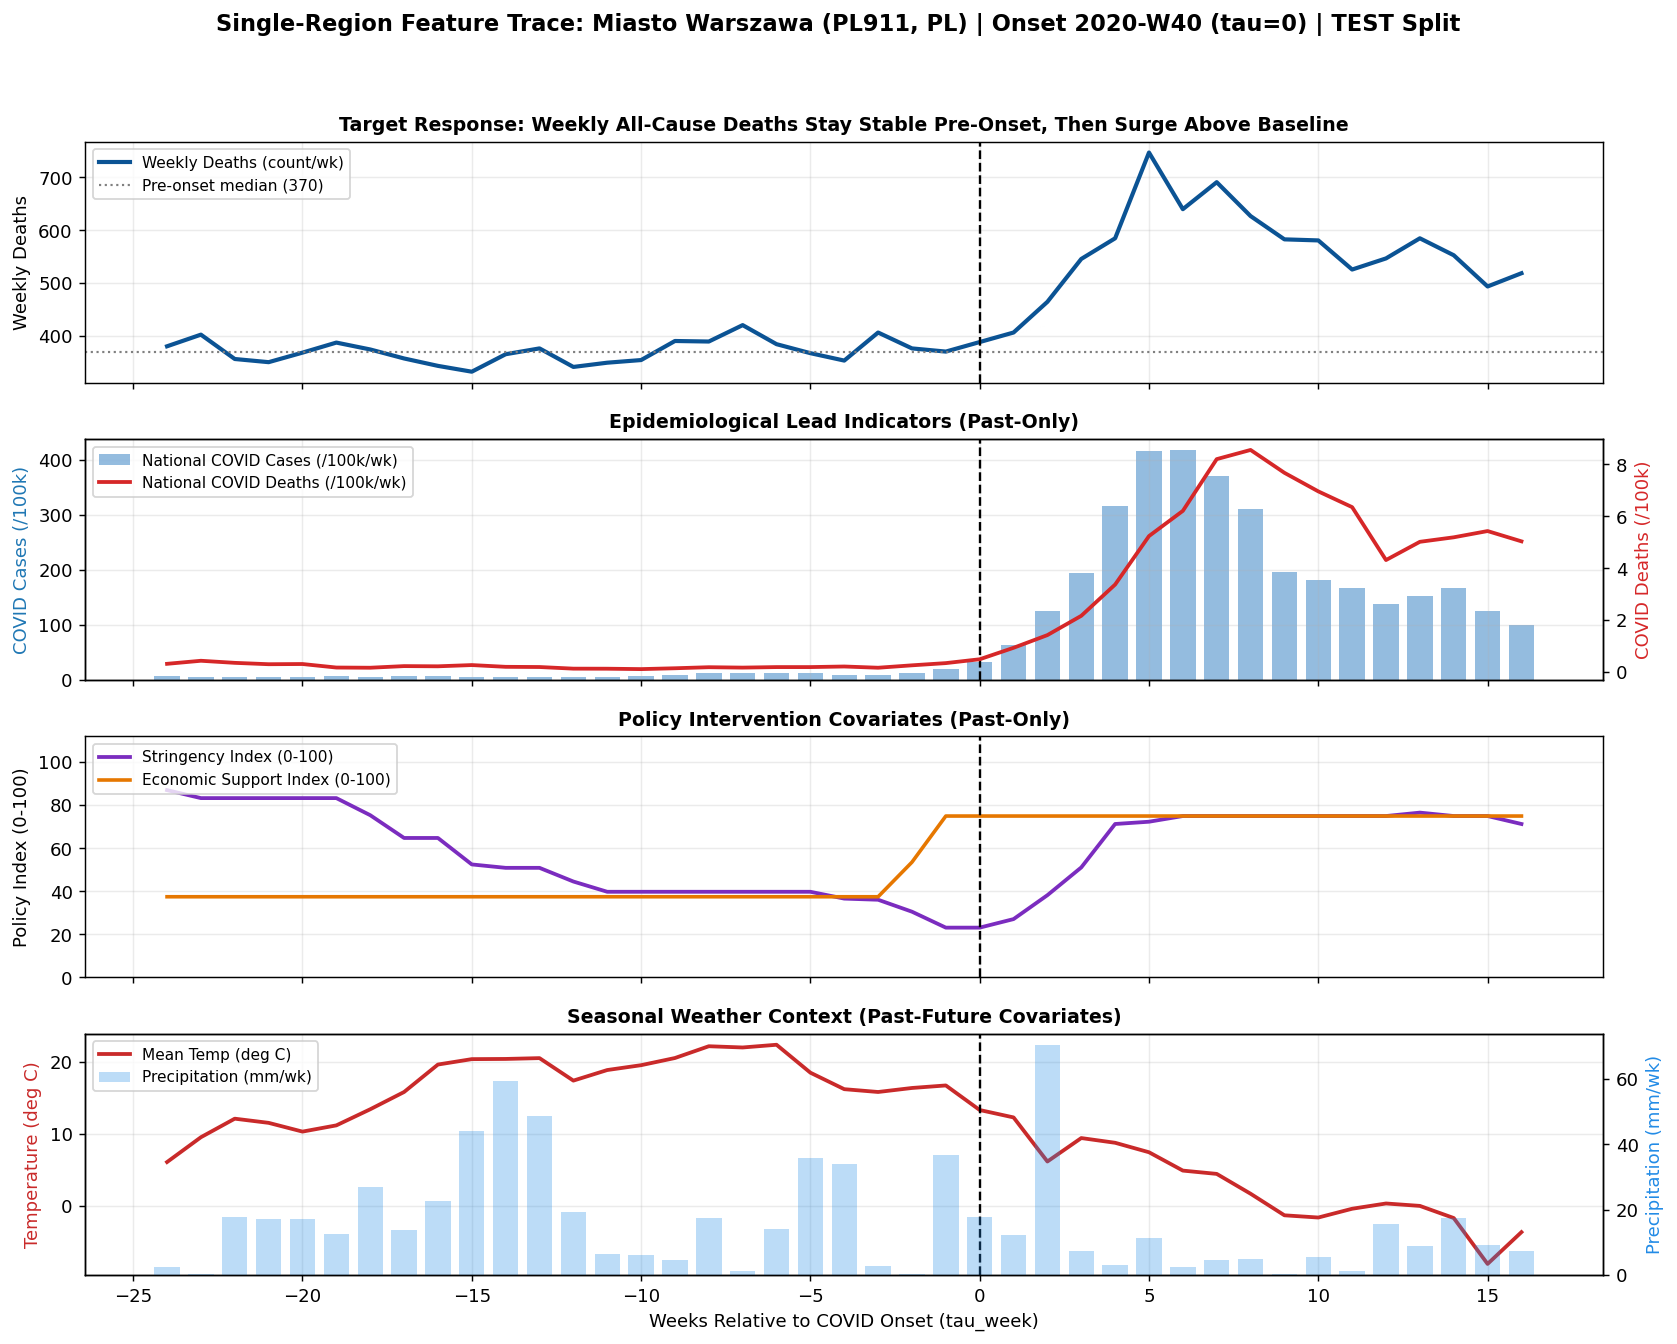

In [4]:
# Pick one clear Test-split region: Miasto Warszawa, Poland (PL911, Fall 2020)
sample = df[df['region_id'] == 'PL911'].sort_values('tau_week')
meta_row = sample.iloc[0]

fig, axes = plt.subplots(4, 1, figsize=(13, 10.5), dpi=130, sharex=True)
fig.suptitle(
    f'Single-Region Feature Trace: {meta_row["region_name"]} ({meta_row["region_id"]}, {meta_row["country_code"]}) | '
    f'Onset {meta_row["onset_week"]} (tau=0) | {meta_row["split"].upper()} Split',
    fontsize=12.5,
    fontweight='bold',
    y=0.98,
)

# 1. Target mortality & trailing excess momentum
axes[0].plot(sample['tau_week'], sample['deaths_total'], color='#0b5394', lw=2.3, label='Weekly Deaths (count/wk)')
axes[0].axhline(meta_row['pre_median_deaths'], color='gray', ls=':', lw=1.2, label=f'Pre-onset median ({meta_row["pre_median_deaths"]:.0f})')
axes[0].set_ylabel('Weekly Deaths')
axes[0].set_title('Target Response: Weekly All-Cause Deaths Stay Stable Pre-Onset, Then Surge Above Baseline', fontweight='bold', fontsize=10.5)
axes[0].legend(loc='upper left', fontsize=8.5)

# 2. Exogenous epidemic lead signal
ax1_r = axes[1].twinx()
b_cases = axes[1].bar(sample['tau_week'], sample['covid_cases_100k'], width=0.75, color='#3d85c6', alpha=0.55, label='National COVID Cases (/100k/wk)')
l_cd, = ax1_r.plot(sample['tau_week'], sample['covid_deaths_100k'], color='#d62728', lw=2.1, label='National COVID Deaths (/100k/wk)')
axes[1].set_ylabel('COVID Cases (/100k)', color='#1f77b4')
ax1_r.set_ylabel('COVID Deaths (/100k)', color='#d62728')
axes[1].set_title('Epidemiological Lead Indicators (Past-Only)', fontweight='bold', fontsize=10.5)
axes[1].legend([b_cases, l_cd], [b_cases.get_label(), l_cd.get_label()], loc='upper left', fontsize=8.5)

# 3. Government containment policy indices
axes[2].plot(sample['tau_week'], sample['stringency_index'], color='#7b2cbf', lw=2.1, label='Stringency Index (0-100)')
axes[2].plot(sample['tau_week'], sample['economic_support_index'], color='#e67700', lw=2.0, label='Economic Support Index (0-100)')
axes[2].set_ylim(0, 112)
axes[2].set_ylabel('Policy Index (0-100)')
axes[2].set_title('Policy Intervention Covariates (Past-Only)', fontweight='bold', fontsize=10.5)
axes[2].legend(loc='upper left', fontsize=8.5)

# 4. Weather context (Past-Future seasonal trajectory)
ax3_r = axes[3].twinx()
l_t, = axes[3].plot(sample['tau_week'], sample['temp_c'], color='#c92a2a', lw=2.1, label='Mean Temp (deg C)')
b_r = ax3_r.bar(sample['tau_week'], sample['rain_mm_week'], width=0.75, color='#228be6', alpha=0.30, label='Precipitation (mm/wk)')
axes[3].set_ylabel('Temperature (deg C)', color='#c92a2a')
ax3_r.set_ylabel('Precipitation (mm/wk)', color='#228be6')
axes[3].set_xlabel('Weeks Relative to COVID Onset (tau_week)')
axes[3].set_title('Seasonal Weather Context (Past-Future Covariates)', fontweight='bold', fontsize=10.5)
axes[3].legend([l_t, b_r], [l_t.get_label(), b_r.get_label()], loc='upper left', fontsize=8.5)

for a in axes:
    a.axvline(0, color='black', ls='--', lw=1.3)
    a.grid(True, alpha=0.25)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('data/covid_mortality_single_region_features.png', dpi=150, bbox_inches='tight')
plt.show()

### 5. Before vs. After $\tau = 0$: Numerical Comparison Across All 505 Regions

In [5]:
# Compare pre-onset (-24w to -1w) vs post-onset (0w to +16w) medians and peaks
before = df[df['tau_week'] < 0]
after = df[df['tau_week'] >= 0]

rows = []
for col, label, role in FEATURES:
    pre_med = before[col].median()
    post_med = after[col].median()
    pre_peak = before.groupby('sample_id')[col].max().median()
    post_peak = after.groupby('sample_id')[col].max().median()
    rows.append({
        'Feature': col,
        'Role': role,
        'Pre-Onset Median': round(pre_med, 2),
        'Post-Onset Median': round(post_med, 2),
        'Pre-Onset Peak Median': round(pre_peak, 2),
        'Post-Onset Peak Median': round(post_peak, 2),
        'Median Shift': round(post_med - pre_med, 2),
    })

summary_tbl = pd.DataFrame(rows)
display(summary_tbl)

,Feature,Role,Pre-Onset Median,Post-Onset Median,Pre-Onset Peak Median,Post-Onset Peak Median,Median Shift
0,deaths_total,PAST-ONLY (TARGET),82.00,103.00,102.00,168.00,21.00
1,deaths_change_1w,PAST-ONLY,0.00,0.00,26.00,41.00,0.00
2,deaths_vs_4w_avg_diff,PAST-ONLY,0.25,-1.00,17.25,37.75,-1.25
3,male_death_share,PAST-ONLY,0.50,0.50,0.61,0.60,0.00
4,covid_cases_100k,PAST-ONLY,0.00,44.67,5.89,94.30,44.67
5,covid_deaths_100k,PAST-ONLY,0.00,3.12,0.14,9.31,3.12
6,stringency_index,PAST-ONLY,7.14,72.22,60.19,79.63,65.08
7,economic_support_index,PAST-ONLY,0.00,75.00,0.00,75.00,75.00
8,temp_c,PAST-FUTURE,9.54,9.84,18.44,18.16,0.29
9,humidity_pct,PAST-FUTURE,83.14,80.73,93.40,87.43,-2.42
